# 📈 01 - Exploratory Data Analysis & Feature Engineering
Notebook này phục vụ phân tích dữ liệu thăm dò (EDA), kiểm tra phân phối target `sales`, phân tích tương quan và trực quan hóa các đặc trưng mùa vụ theo đề bài **Practice 2: Predicting Product Sales**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Tìm thư mục gốc dù Jupyter được mở từ thư mục dự án hay thư mục notebooks.
ROOT_DIR = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "README.md").exists()),
    Path.cwd().parent,
)
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src import config
from src.data.builder import build_product_week_panel
from src.data.feature_engineering import engineer_product_week_features

sns.set_theme(style="whitegrid")

## 1. Tải và Khám phá Dữ liệu (Data Inspection)

In [3]:
# Dùng lại panel đã có; nếu chưa tồn tại thì tạo từ sáu bảng dữ liệu Olist.
if config.FEATURED_WEEKLY_PANEL_FILE.exists():
    df = pd.read_csv(config.FEATURED_WEEKLY_PANEL_FILE, parse_dates=["week_start"])
else:
    if config.WEEKLY_PANEL_FILE.exists():
        weekly_panel = pd.read_csv(config.WEEKLY_PANEL_FILE, parse_dates=["week_start"])
    else:
        weekly_panel = build_product_week_panel()
    df = engineer_product_week_features(weekly_panel)
    df.to_csv(config.FEATURED_WEEKLY_PANEL_FILE, index=False)

print(f"Weekly panel shape: {df.shape}")
print(f"Time range: {df['week_start'].min():%Y-%m-%d} to {df['week_start'].max():%Y-%m-%d}")
display(df.head())
display(df.dtypes.rename("dtype").to_frame())

Weekly panel shape: (1262576, 26)
Time range: 2016-09-12 to 2018-08-27


,product_id,week_start,category,sales,units_sold,order_count,review_count,rating_sum,new_customer_states,avg_price_last_observed,...,product_age_weeks,reviews_count_prior,rating_mean_prior,cumulative_customer_spend,purchase_frequency_prior,geographic_dispersion_prior,month,quarter,week_of_year,is_peak_shopping_season
0,00066f42aeeb9f3007548bb9d3f33c38,2018-05-14,perfumery,101.65,1,1,0,0.0,1,NaN,...,0,0.0,NaN,0.00,0.0,0.0,5,2,20,0
1,00066f42aeeb9f3007548bb9d3f33c38,2018-05-21,perfumery,0.00,0,0,0,0.0,0,101.65,...,1,0.0,NaN,101.65,1.0,1.0,5,2,21,0
2,00066f42aeeb9f3007548bb9d3f33c38,2018-05-28,perfumery,0.00,0,0,0,0.0,0,101.65,...,2,0.0,NaN,101.65,1.0,1.0,5,2,22,0
3,00066f42aeeb9f3007548bb9d3f33c38,2018-06-04,perfumery,0.00,0,0,1,5.0,0,101.65,...,3,0.0,NaN,101.65,1.0,1.0,6,2,23,0
4,00066f42aeeb9f3007548bb9d3f33c38,2018-06-11,perfumery,0.00,0,0,0,0.0,0,101.65,...,4,1.0,5.0,101.65,1.0,1.0,6,2,24,0


,dtype
product_id,str
week_start,datetime64[us]
category,str
sales,float64
units_sold,int64
order_count,int64
review_count,int64
rating_sum,float64
new_customer_states,int64
avg_price_last_observed,float64


## 2. Phân bố Biến Mục Tiêu (Target Variable: Sales)
Kiểm tra độ lệch (skewness) của biến doanh số để cân nhắc biến đổi Log transform nếu cần.

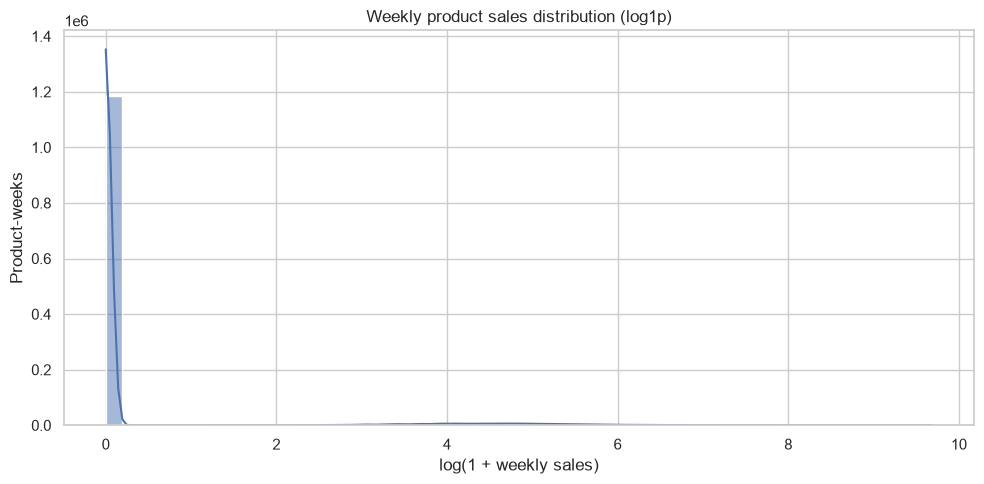

In [4]:
# Dùng log1p để thể hiện cả khối lượng doanh thu bằng 0 và phần đuôi lệch phải.
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(np.log1p(df[config.WEEKLY_TARGET_COLUMN]), bins=50, kde=True, ax=ax)
ax.set(title="Weekly product sales distribution (log1p)", xlabel="log(1 + weekly sales)", ylabel="Product-weeks")
fig.tight_layout()
fig.savefig(config.NOTEBOOK_FIGURES_DIR / "task1_01_sales_distribution.png", dpi=config.FIGURE_DPI)
plt.show()

## 3. Ma trận tương quan (Correlation Matrix)

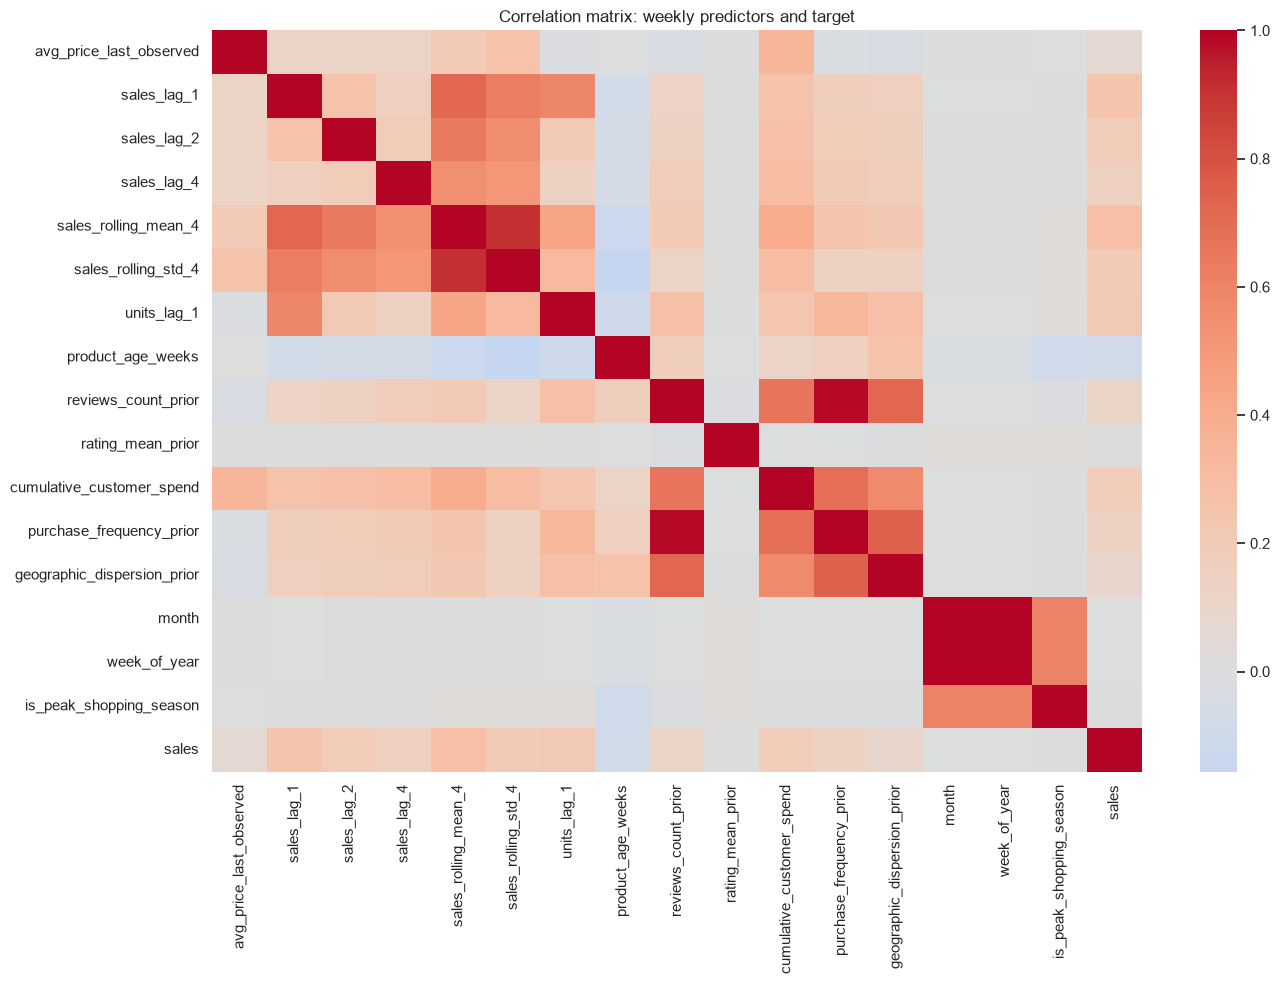

In [5]:
# Tính tương quan giữa các đầu vào số học và biến mục tiêu doanh thu tuần.
correlation_columns = config.WEEKLY_NUMERICAL_FEATURES + [config.WEEKLY_TARGET_COLUMN]
correlation = df[correlation_columns].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(correlation, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix: weekly predictors and target")
fig.tight_layout()
fig.savefig(config.NOTEBOOK_FIGURES_DIR / "task1_08_correlation_heatmap.png", dpi=config.FIGURE_DPI)
plt.show()

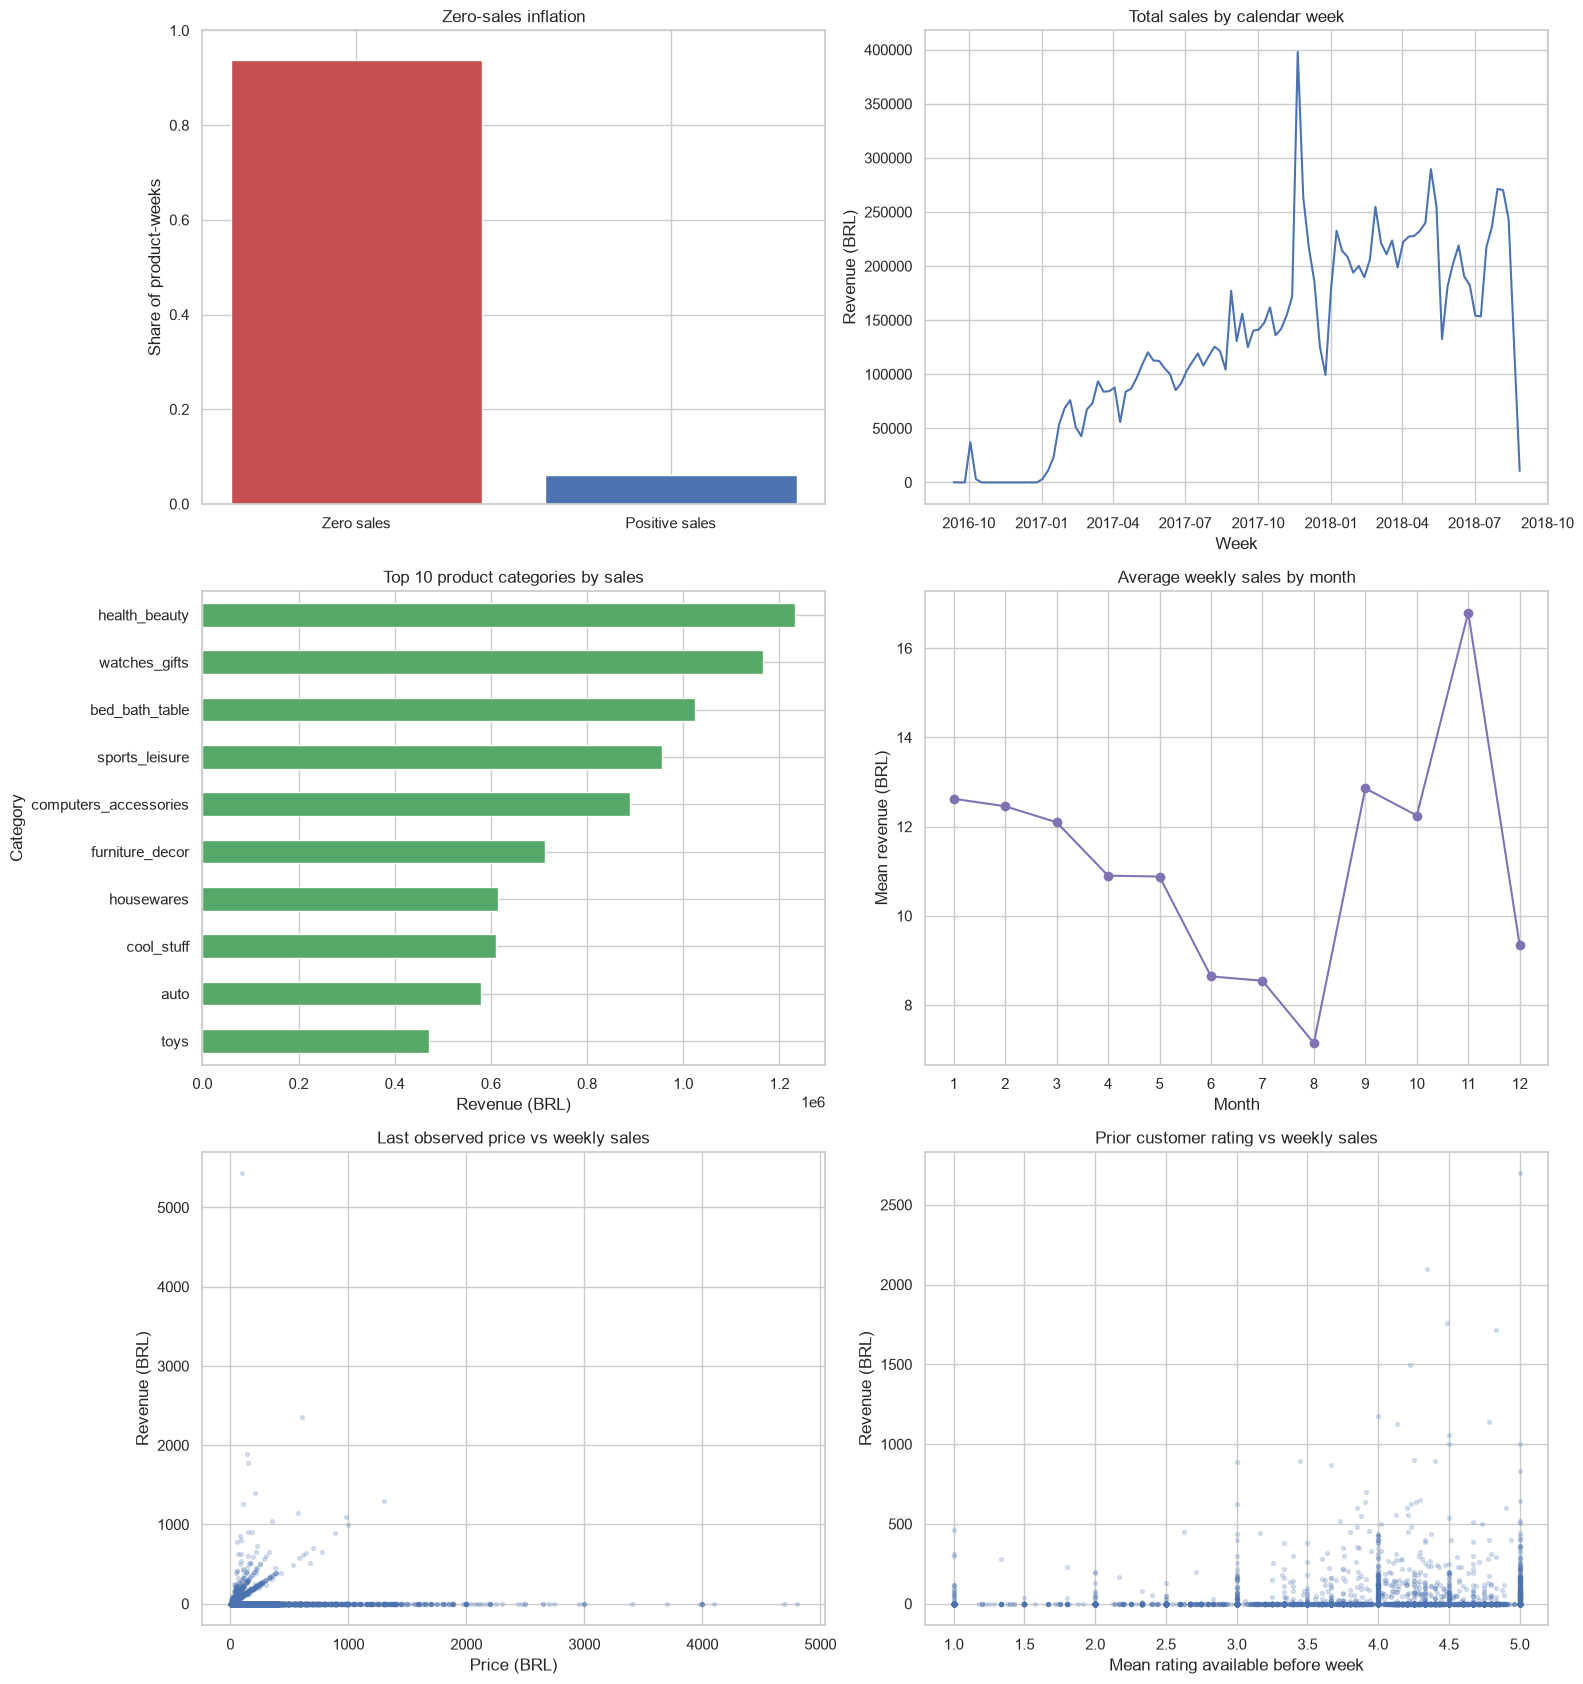

Zero-sales product-week share: 93.8%


In [6]:
# Sáu biểu đồ bổ sung hoàn thiện báo cáo EDA gồm tám biểu đồ của Task 1.
fig, axes = plt.subplots(3, 2, figsize=(16, 17))

zero_share = df[config.WEEKLY_TARGET_COLUMN].eq(0).mean()
axes[0, 0].bar(["Zero sales", "Positive sales"], [zero_share, 1 - zero_share], color=["#c44e52", "#4c72b0"])
axes[0, 0].set(title="Zero-sales inflation", ylabel="Share of product-weeks", ylim=(0, 1))

weekly_total = df.groupby("week_start")[config.WEEKLY_TARGET_COLUMN].sum()
axes[0, 1].plot(weekly_total.index, weekly_total.values, color="#4c72b0")
axes[0, 1].set(title="Total sales by calendar week", xlabel="Week", ylabel="Revenue (BRL)")

category_sales = df.groupby("category")[config.WEEKLY_TARGET_COLUMN].sum().nlargest(10).sort_values()
category_sales.plot.barh(ax=axes[1, 0], color="#55a868")
axes[1, 0].set(title="Top 10 product categories by sales", xlabel="Revenue (BRL)", ylabel="Category")

monthly_sales = df.groupby("month")[config.WEEKLY_TARGET_COLUMN].mean().reindex(range(1, 13))
axes[1, 1].plot(monthly_sales.index, monthly_sales.values, marker="o", color="#8172b3")
axes[1, 1].set(title="Average weekly sales by month", xlabel="Month", ylabel="Mean revenue (BRL)", xticks=range(1, 13))

sample = df.loc[df["avg_price_last_observed"].notna()].sample(
    n=min(20000, df["avg_price_last_observed"].notna().sum()), random_state=config.RANDOM_STATE
)
axes[2, 0].scatter(sample["avg_price_last_observed"], sample[config.WEEKLY_TARGET_COLUMN], alpha=0.2, s=8)
axes[2, 0].set(title="Last observed price vs weekly sales", xlabel="Price (BRL)", ylabel="Revenue (BRL)")

rated = df.loc[df["rating_mean_prior"].notna()]
if not rated.empty:
    rated = rated.sample(n=min(20000, len(rated)), random_state=config.RANDOM_STATE)
    axes[2, 1].scatter(rated["rating_mean_prior"], rated[config.WEEKLY_TARGET_COLUMN], alpha=0.2, s=8)
axes[2, 1].set(title="Prior customer rating vs weekly sales", xlabel="Mean rating available before week", ylabel="Revenue (BRL)")

fig.tight_layout()
fig.savefig(config.NOTEBOOK_FIGURES_DIR / "task1_eda_six_supporting_charts.png", dpi=config.FIGURE_DPI)
plt.show()
print(f"Zero-sales product-week share: {zero_share:.1%}")